In [1]:
from PolSARInversion import AdamLearner

import numpy as np
import scipy
import matplotlib.pyplot as plt

In [43]:
#params = np.zeros((4, 100, 100))
#params[0] = 1
#params[1] = 2
#params[2] = 3
#params[3] = 4
#params.reshape(4, params.shape[1]*params.shape[2]).T.reshape(params.shape[1:])

ValueError: cannot reshape array of size 40000 into shape (100,100)

In [32]:
slice_hgt = np.linspace(0, 1, 20)
block_hgt = np.linspace(0.1, 1, 20)
block_age = np.linspace(10, 300, 20)

#slice_hgt, block_hgt, block_age = np.meshgrid(slice_hgt, block_hgt, block_age, indexing='ij')

def reflectivity(z, h, t):
    return 35*(1 - z/h)/(0.1*t)

In [37]:
#reflectivity(*np.meshgrid(slice_hgt, block_hgt, block_age, indexing='ij'))

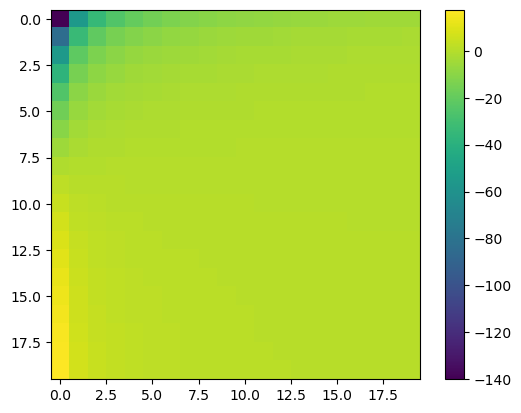

In [31]:
plt.imshow(np.trapezoid(reflectivity(slice_hgt,block_hgt,block_age),slice_hgt[:,0,0], axis=0))
plt.colorbar()

In [45]:
class RVoW(AdamLearner):
    '''Adaptation of RVoG-like inversion to sea ice
    (src: custom)

    Models the interferometric coherence at a known incidence angle and incidence angle offset
    '''
    def __init__(self, coherences, extinction_func, incidence_angle, incidence_angle_delta, wavelength = 0.12):
        self.coherences = coherences
        self.wavelength = wavelength
        self.incidence_angle=incidence_angle
        
        self.k_z = 4*np.pi*incidence_angle_delta/(wavelength*np.sin(incidence_angle_map))
        self.k_z[np.isinf(self.k_z)] = np.nan

        self.init_learning()
        self.init_params()
        self.init_vol_coh(extinction_func)
        self.find_icesurf_phase()

    def init_vol_coh(self, extinction_func, hgt_min=0.1, hgt_max=1, hgt_bins=20, age_min=10, age_max=200, age_bins=20):
        '''Takes a function and integrates it over ranges to initialise a polynomial curve fit.
        extinction_func(z, hgt, age) -> extinction coefficient'''
        print("Beginning coherence function mapping...")
        z = np.linspace(0, hgt_max, int(hgt_bins + hgt_min*(hgt_max-hgt_min)/hgt_bins))
        hgts = np.linspace(hgt_min, hgt_max, hgt_bins)
        ages = np.linspace(age_min, age_max, age_bins)
        x = extinction_func(*np.meshgrid(z, hgts, ages, indexing='ij'))
        #  y_V = integral(np.exp(-A(z) + 1j*self.k_z*z)) / integral(np.exp(-A(z))
        x = np.trapezoid(np.exp(-x + 1j*self.k_z*z), z, axis=0) / np.trapezoid(np.exp(-x), z, axis=0)
        self.vol_coh = scipy.interpolate.RegularGridInterpolator((z, hgts, ages), x)
        print("coherence function initialized.")

    def find_icesurf_phase(self):
        #step 1 - extract highest coherence polarimetric basis unit
        #step 2 - extract corresponding signal
        self.icesurf_phase = self.coherences[ np.argmax(np.abs(self.coherences), axis=0),
            np.arange(self.coherences.shape[1])[:,None], np.arange(self.coherences.shape[2]) ]
        self.icesurf_phase = np.arctan2(np.imag(self.icesurf_phase), np.real(self.icesurf_phase))
    
    def init_params(self):
        self.params = np.zeros((3+self.coherences.shape[0], self.coherences.shape[1], self.coherences.shape[2]))
        self.params[0] = 0 #ice thickness (m)
        self.params[1] = 0 #ice age (days)
        self.params[2] = 0 #
        self.params[3:] = 0.5 #polarimetric 'ground'-volume ratio
        pass

    def data_modelled(self, params):
        vcohs = self.vol_coh(params.reshape(params.shape[0], params.shape[1]*params.shape[2]).T).reshape(params.shape[1:])
        icebott_phase = self.icesurf_phase + (2*np.pi*params[0]/(self.wavelength*np.cos(self.incidence_angle)))
        cohs = np.exp(1j * icebott_phase) * (vcohs + params[3:]) / (1 + params[3:])
        return cohs
        #return self.coh_modelled_jit(params, self.wavelength, self.incidence_angle, self.k_z)

    #@staticmethod
    #@nb.njit(cache=True, fastmath=True, parallel=True)
    #def coh_modelled_jit(params, wvl, ia, k_z, ip, r_int):